In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the movies data with 'latin1' encoding
movies = pd.read_csv('movies.dat', sep='::', names=['MovieID', 'Title', 'Genres'], engine='python', encoding='latin1')

# Load the ratings data with 'latin1' encoding
ratings = pd.read_csv('ratings.dat', sep='::', names=['UserID', 'MovieID', 'Rating', 'Timestamp'], engine='python', encoding='latin1')

# Load the users data with 'latin1' encoding
users = pd.read_csv('users.dat', sep='::', names=['UserID', 'Gender', 'Age', 'Occupation', 'Zip-code'], engine='python', encoding='latin1')

# Merge the ratings and users DataFrames
merged = pd.merge(pd.merge(ratings, users), movies)



In [42]:
# Split the genres column and create a new entry for each genre
merged = merged.assign(Genres = merged['Genres'].str.split('|')).explode('Genres')

# get the unique genres
genres = merged['Genres'].unique()

# save the number of arms
n_arms = len(genres)


# Initialize the algorithm
counts = {genre: 0 for genre in genres}
averages = {genre: 0 for genre in genres}

# Define the horizon and the number of experiments
n = 50000
num_experiments = 10



# Calculate the frequency of each rating for each genre
rating_freq = merged.groupby('Genres')['Rating'].value_counts(normalize=True)

# Pre-calculate the ratings and probabilities arrays for each genre
rating_dist = {genre: (rating_freq[genre].index, rating_freq[genre].values)
               for genre in rating_freq.index.levels[0]}

def pull_arm(chosen_genre):
    # Check if there are any movies of this genre left
    if chosen_genre not in rating_dist:
        return 0

    # Sample a rating from the pre-calculated distribution
    ratings, probabilities = rating_dist[chosen_genre]
    reward = ratings[np.random.multinomial(1, probabilities).argmax()]

    return reward




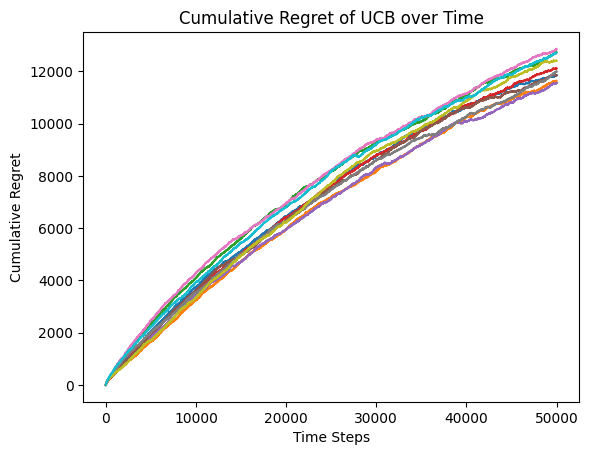

In [45]:
np.random.seed(122)


# Map each genre to an index
genre_to_index = {genre: i for i, genre in enumerate(genres)}

B = 4  # Constant for adjusting the degree of exploration

cumulative_regret = np.zeros((num_experiments, n+1))


# Run the UCB algorithm
for experiment in range(num_experiments):
    # Reset the counts, averages, and cumulative regret at the start of each experiment
    counts = {genre: 0 for genre in genres}
    averages = {genre: 0 for genre in genres}

    for t in range(1, n+1):
        # Calculate the UCB index for each arm
        ucb_indices = {genre: averages[genre] + B * np.sqrt((4 * np.log(t)) / (1 + counts[genre])) for genre in genres}
        
        # Choose the arm with the highest UCB index
        chosen_arm = max(ucb_indices, key=ucb_indices.get)
        
        # Pull the chosen arm and get the reward
        reward = pull_arm(chosen_arm)
        
        # Update the counts and averages
        counts[chosen_arm] += 1
        averages[chosen_arm] = ((averages[chosen_arm] * (counts[chosen_arm] - 1)) + reward) / counts[chosen_arm]
        
        # Calculate the regret
        optimal_reward = max(averages.values())
        regret = optimal_reward - reward
        
        # Store the cumulative regret
        cumulative_regret[experiment, t] = cumulative_regret[experiment, t-1] + regret



# Plot the cumulative regret
for experiment in range(num_experiments):
    plt.plot(cumulative_regret[experiment])
plt.xlabel('Time Steps')  # X-axis label
plt.ylabel('Cumulative Regret')  # Y-axis label
plt.title('Cumulative Regret of UCB over Time')  # Title of the plot
plt.show()
